# Case file 1 · The Evidence Room: meet the sprites

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/01_meet_the_sprites.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Companion notebook to part 1 of *Through the Thicket to Inference*.
We download real evidence, about 94,000 tiny pictures, and look at what a sprite is made of.

**Time:** about 2 minutes on a laptop. **You will learn:** pixels, RGB, alpha (transparency), what a dataset row looks like.

In [1]:
# On Colab or a fresh computer, install the package once (about a minute). If it is already installed, this does nothing.
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import numpy as np
from IPython.display import display
from pixelsprite import sheet
from pixelsprite.data import load_shard

# One shard of the Pixel Art Atlas: ~29 MB, ~94k sprites. We decode 3,000 random ones.
sprites = load_shard(n=3000, seed=0)
print(len(sprites), "sprites, array shape", sprites.rgba.shape)

3000 sprites, array shape (3000, 16, 16, 4)


## 1. Look at the evidence
`sheet` draws sprites enlarged 4×, on a grey checkerboard so you can see which pixels are transparent.

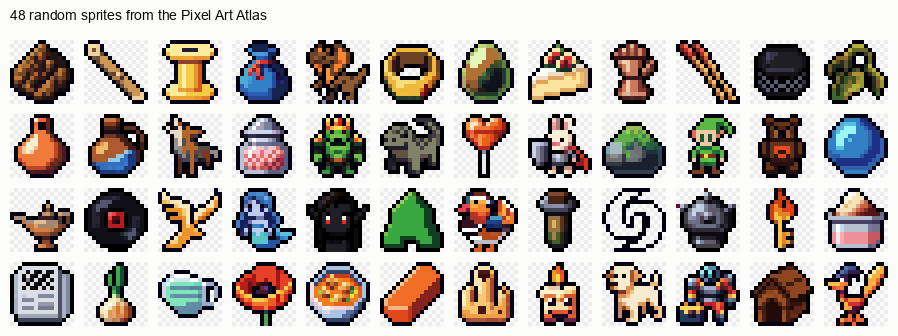

- top-down messy lumber pile with a small crack in earthy colors
- top-down long bamboo pole with a slanted cut end
- empty yellow bobbin
- crumpled blue gift bag
- hissing brown dilophosaurus with clawed hands in flat colors
- rigid yellow neck brace with hook straps in earthy colors
- egg-shaped soul orb in earthy colors
- front-view runny wedge of brie with fig slices


In [3]:
display(sheet(list(sprites.rgba[:48]), "48 random sprites from the Pixel Art Atlas", scale=4, cols=12))
for c in sprites.caption[:8]:
    print("-", c)

## 2. Anatomy of one sprite
A sprite is a grid of 16 × 16 = 256 pixels. Each pixel has four numbers from 0 to 255:
**R**ed, **G**reen, **B**lue light, and **A**lpha, which says how see-through the pixel is.
Here alpha is either 0 (empty, see-through) or 255 (solid).

caption: front-view runny wedge of brie with fig slices
shape: (16, 16, 4)   dtype: uint8
pixel (row 8, column 8) = [238 221 196 255]  -> R, G, B, A
alpha values used: [  0 255]


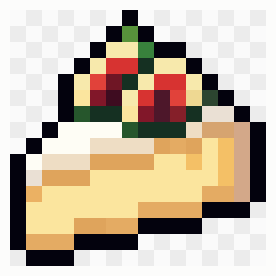

.......#........
......###.......
.....######.....
....########....
...##########...
...###########..
...############.
..##############
.###############
################
################
################
###############.
############....
########........
.###............


In [4]:
i = 7
s = sprites.rgba[i]
print("caption:", sprites.caption[i])
print("shape:", s.shape, "  dtype:", s.dtype)
print("pixel (row 8, column 8) =", s[8, 8], " -> R, G, B, A")
print("alpha values used:", np.unique(s[..., 3]))
display(sheet([s], scale=16, cols=1))

# The alpha channel as a picture made of characters: '#' = solid, '.' = empty
for row in s[..., 3]:
    print("".join("#" if a else "." for a in row))

## 3. How many colours?
A screen can show 256³ ≈ 16.7 million colours. Count how many the sprites actually use.

In [5]:
solid = sprites.rgba[sprites.mask]                       # every solid pixel, shape (P, 4)
colours = np.unique(solid[:, :3], axis=0)
per_sprite = [len(np.unique(x[x[..., 3] > 0][:, :3], axis=0)) for x in sprites.rgba]
print(f"{len(solid):,} solid pixels use {len(colours):,} different colours")
print("colours per sprite: median", int(np.median(per_sprite)), " max", max(per_sprite))
print("share of the canvas that is solid:", round(sprites.mask.mean(), 3))
# Clue: the whole dataset (1.4 million sprites) uses exactly 4,096 = 16 x 16 x 16 colours. Someone already squeezed
# every picture into a fixed palette before we got it.

466,951 solid pixels use 4,027 different colours
colours per sprite: median 21  max 76
share of the canvas that is solid: 0.608


## 4. A precaution: upscaled pictures
Image files sometimes store a small sprite enlarged, e.g. a 16×16 sprite as 64×64 with 4×4 blocks of one colour.
`detect_scale` finds the largest block size that makes the picture out of single-colour squares. We checked the
whole dataset this way: only 2 of 1.4 million sprites were stored enlarged. Checking was still the right call.

In [6]:
from pixelsprite.images import detect_scale
big = s.repeat(4, 0).repeat(4, 1)                         # pretend someone saved it at 64x64
print("upscaled shape:", big.shape, "-> detected scale:", detect_scale(big))
small = big[::4, ::4]
print("restored exactly:", np.array_equal(small, s))

upscaled shape: (64, 64, 4) -> detected scale: 4
restored exactly: True


## Your turn
1. Change `i` in section 2 and look at other sprites. Can you guess the caption from the alpha picture alone?
2. Find all sprites whose caption contains a word you like (try `"sword"`), and show them with `sheet`.

```python
picks = [x for x, c in zip(sprites.rgba, sprites.caption) if "sword" in c]
display(sheet(picks[:24], "swords", scale=4, cols=12))
```